# Forecasting Gold Prices with XGBoost and SHAP

Predicts the monthly gold price (USD/oz) from 7 macroeconomic indicators, compares six regression models,
and uses **SHAP** to explain which indicators drive the predictions.

Based on: Ben Jabeur, S., Mefteh-Wali, S., & Viviani, J.-L. (2024). *Forecasting gold price with the XGBoost
algorithm and SHAP interaction values.* Annals of Operations Research, 334, 679–699.
[doi:10.1007/s10479-021-04187-w](https://doi.org/10.1007/s10479-021-04187-w)

**Data:** `data/gold_macro_monthly_1986_2019.csv` – 408 monthly rows (Jan 1986 – Dec 2019).
**Outputs:** tables and charts are written to `results/`.

## Setup
In Google Colab, uncomment the install line first.

In [1]:
# !pip install -q xgboost lightgbm catboost shap

import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor
import shap

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

## 1. Load the dataset

In [2]:
CSV_PATH = "data/gold_macro_monthly_1986_2019.csv"
if not os.path.exists(CSV_PATH):  # e.g. when opened directly in Colab
    CSV_PATH = ("https://raw.githubusercontent.com/srikarasudan/gold-price-forecasting-xgboost-shap/"
                "main/data/gold_macro_monthly_1986_2019.csv")
df = pd.read_csv(CSV_PATH, parse_dates=["Date"]).set_index("Date")
df = df.dropna(how="all")

print("Rows:", len(df), "| Period:", df.index.min().date(), "to", df.index.max().date())
print("Columns:", df.columns.tolist())
df.head()

Rows: 408 | Period: 1986-01-01 to 2019-12-01
Columns: ['Gold', 'Silver', 'Oil', 'USD_EUR', 'USD_CNY', 'SP_500', 'Iron_ore', 'Inflation']


,Gold,Silver,Oil,USD_EUR,USD_CNY,SP_500,Iron_ore,Inflation
Date,,,,,,,,
1986-01-01,278.299988,5.003,33.099998,1.259002,8.2768,211.779999,93.9,109.9
1986-02-01,278.299988,5.003,33.099998,1.259002,8.2768,226.919998,93.8,109.7
1986-03-01,278.299988,5.003,33.099998,1.259002,8.2768,238.899994,93.8,109.1
1986-04-01,278.299988,5.003,33.099998,1.259002,8.2768,235.520004,93.8,108.7
1986-05-01,278.299988,5.003,33.099998,1.259002,8.2768,247.350006,93.8,109.0


## 2. Descriptive statistics

In [3]:
def descriptive_stats(df_in):
    desc = df_in.describe().T
    desc["skewness"] = df_in.skew()
    desc["kurtosis"] = df_in.kurtosis()
    return desc[["mean", "50%", "max", "min", "std", "skewness", "kurtosis"]].rename(columns={"50%": "median"})

descriptive_stats(df).round(3)

,mean,median,max,min,std,skewness,kurtosis
Gold,665.624,337.500,1828.500,257.900,481.532,0.768,-1.000
Silver,10.864,5.003,48.584,4.128,8.241,1.534,2.235
Oil,50.264,33.100,140.000,19.440,24.635,1.154,0.263
USD_EUR,1.264,1.259,1.576,1.058,0.085,0.560,2.220
USD_CNY,7.639,8.277,8.278,6.051,0.825,-0.698,-1.285
SP_500,1154.053,1128.205,3221.290,211.780,710.587,0.768,0.066
Iron_ore,110.663,95.600,192.700,79.400,27.189,0.720,-0.425
Inflation,184.466,182.200,258.630,108.700,43.410,-0.041,-1.225


## 3. Correlation and p-values

In [4]:
def corr_and_pvals(df_in):
    cols = df_in.columns
    corr = df_in.corr()
    pvals = pd.DataFrame(np.ones((len(cols), len(cols))), columns=cols, index=cols)
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            xy = df_in[[cols[i], cols[j]]].dropna()
            p = pearsonr(xy.iloc[:, 0], xy.iloc[:, 1])[1] if len(xy) > 3 else np.nan
            pvals.iloc[i, j] = pvals.iloc[j, i] = p
    np.fill_diagonal(pvals.values, 0.0)
    return corr, pvals

corr, pvals = corr_and_pvals(df)
print("Correlation matrix:")
display(corr.round(3))
print("P-values:")
display(pvals.round(4))

Correlation matrix:


,Gold,Silver,Oil,USD_EUR,USD_CNY,SP_500,Iron_ore,Inflation
Gold,1.000,0.934,0.785,0.009,-0.959,0.727,0.906,0.869
Silver,0.934,1.000,0.841,0.223,-0.872,0.538,0.884,0.741
Oil,0.785,0.841,1.000,0.495,-0.784,0.452,0.824,0.675
USD_EUR,0.009,0.223,0.495,1.000,-0.051,-0.323,0.164,-0.081
USD_CNY,-0.959,-0.872,-0.784,-0.051,1.000,-0.696,-0.856,-0.850
SP_500,0.727,0.538,0.452,-0.323,-0.696,1.000,0.654,0.899
Iron_ore,0.906,0.884,0.824,0.164,-0.856,0.654,1.000,0.851
Inflation,0.869,0.741,0.675,-0.081,-0.850,0.899,0.851,1.000


P-values:


,Gold,Silver,Oil,USD_EUR,USD_CNY,SP_500,Iron_ore,Inflation
Gold,0.0000,0.0,0.0,0.8591,0.0000,0.0,0.0000,0.0000
Silver,0.0000,0.0,0.0,0.0000,0.0000,0.0,0.0000,0.0000
Oil,0.0000,0.0,0.0,0.0000,0.0000,0.0,0.0000,0.0000
USD_EUR,0.8591,0.0,0.0,0.0000,0.3088,0.0,0.0009,0.1037
USD_CNY,0.0000,0.0,0.0,0.3088,0.0000,0.0,0.0000,0.0000
SP_500,0.0000,0.0,0.0,0.0000,0.0000,0.0,0.0000,0.0000
Iron_ore,0.0000,0.0,0.0,0.0009,0.0000,0.0,0.0000,0.0000
Inflation,0.0000,0.0,0.0,0.1037,0.0000,0.0,0.0000,0.0000


## 4. Target and features

In [5]:
TARGET = "Gold"
X = df.drop(columns=[TARGET]).ffill().bfill()
y = df[TARGET]
X.columns.tolist()

['Silver', 'Oil', 'USD_EUR', 'USD_CNY', 'SP_500', 'Iron_ore', 'Inflation']

## 5. Train/test split

60% of the months are used for training and 40% for testing, with **no overlap** between the two sets.
The test months are sorted by date so they can be plotted as a time series.

> **Note:** an earlier version of this notebook trained on all 408 months (`X_train = X`), so the test months
> were also in the training data and XGBoost scored an unrealistic R² of 0.9999. This version fixes that.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=RANDOM_STATE
)
X_test, y_test = X_test.sort_index(), y_test.sort_index()
print(f"Samples: total={len(X)}, train={len(X_train)}, test={len(X_test)}")
assert X_train.index.intersection(X_test.index).empty, 'train and test overlap'


Samples: total=408, train=244, test=164


## 6. Scaling (for Linear Regression and the Neural Network)

In [7]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), index=X_train.index, columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), index=X_test.index, columns=X_test.columns)

## 7. Models

In [8]:
models = {
    "Linear Regression": LinearRegression(),
    "Neural Network": MLPRegressor(hidden_layer_sizes=(50, 50), max_iter=1000, random_state=RANDOM_STATE,
                                   early_stopping=True, validation_fraction=0.1),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "LightGBM": lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31, subsample=0.7,
                                  random_state=RANDOM_STATE, verbose=-1),
    "CatBoost": CatBoostRegressor(iterations=500, learning_rate=0.05, depth=5, random_state=RANDOM_STATE,
                                  thread_count=4, silent=True),
    "XGBoost": xgb.XGBRegressor(colsample_bytree=0.7, learning_rate=0.05, n_estimators=500, max_depth=5,
                                subsample=0.7, min_child_weight=4, n_jobs=4, random_state=RANDOM_STATE),
}

## 8. Train, predict and evaluate

In [9]:
results, trained_models, predictions = {}, {}, {}

for name, model in models.items():
    if name in ("Neural Network", "Linear Regression"):
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    results[name] = {"RMSE": np.sqrt(mse), "MSE": mse,
                     "MAE": mean_absolute_error(y_test, y_pred), "R²": r2_score(y_test, y_pred)}
    trained_models[name] = model
    predictions[name] = pd.Series(y_pred, index=y_test.index)

results_df = pd.DataFrame(results).T.round(4).sort_values("R²", ascending=False)
results_df.to_csv(f"{RESULTS_DIR}/model_performance.csv")
results_df

,RMSE,MSE,MAE,R²
XGBoost,28.9974,840.8514,14.1139,0.9962
Random Forest,29.6712,880.3783,14.9553,0.9961
CatBoost,30.7678,946.6566,16.9173,0.9958
LightGBM,46.2641,2140.3637,21.4558,0.9904
Linear Regression,55.9017,3125.0048,41.4717,0.9860
Neural Network,92.0858,8479.8009,55.7092,0.9621


## 9. Actual vs predicted (all models)

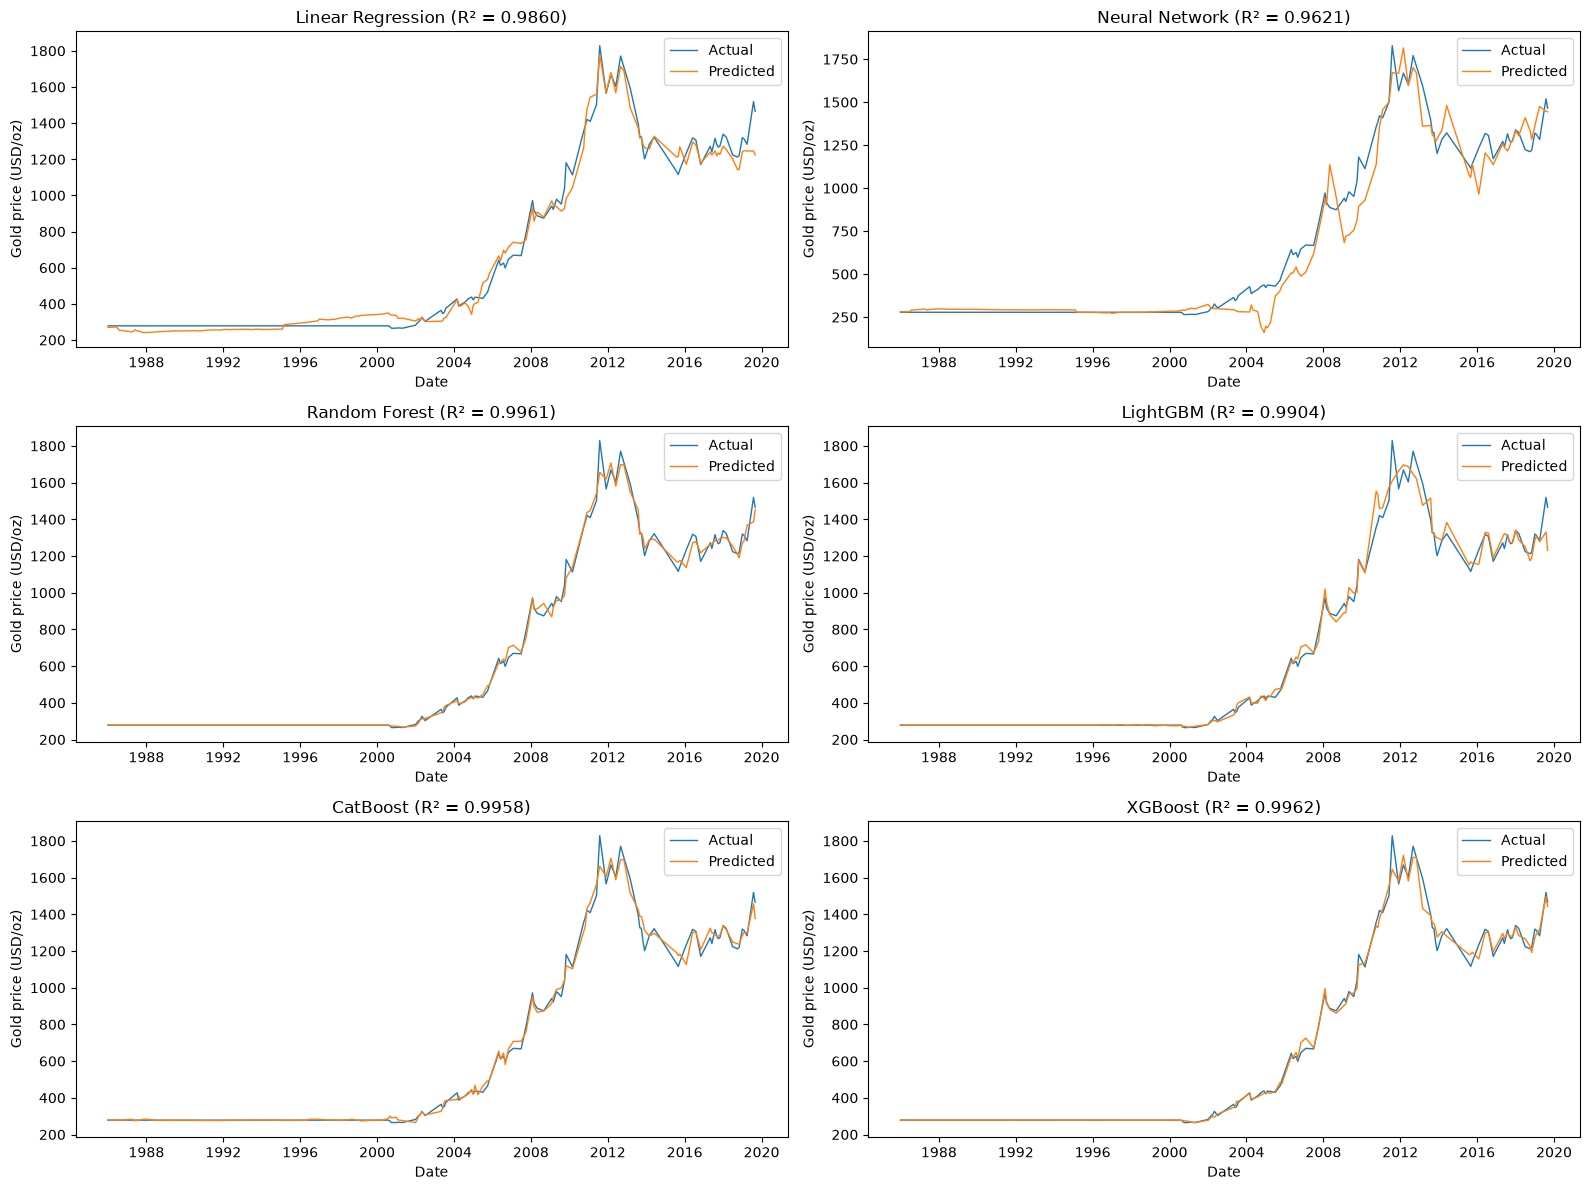

In [10]:
rows = int(np.ceil(len(predictions) / 2))
plt.figure(figsize=(16, 4 * rows))
for i, (name, pred) in enumerate(predictions.items(), 1):
    ax = plt.subplot(rows, 2, i)
    ax.plot(y_test.index, y_test.values, label="Actual", linewidth=1)
    ax.plot(pred.index, pred.values, label="Predicted", linewidth=1)
    ax.set_title(f"{name} (R² = {results[name]['R²']:.4f})")
    ax.set_xlabel("Date")
    ax.set_ylabel("Gold price (USD/oz)")
    ax.legend()
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/actual_vs_predicted.png", dpi=150)
plt.show()

## 10. SHAP analysis (XGBoost)

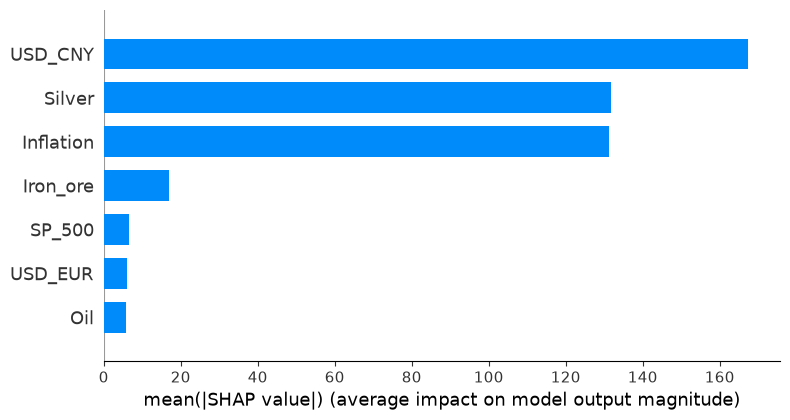

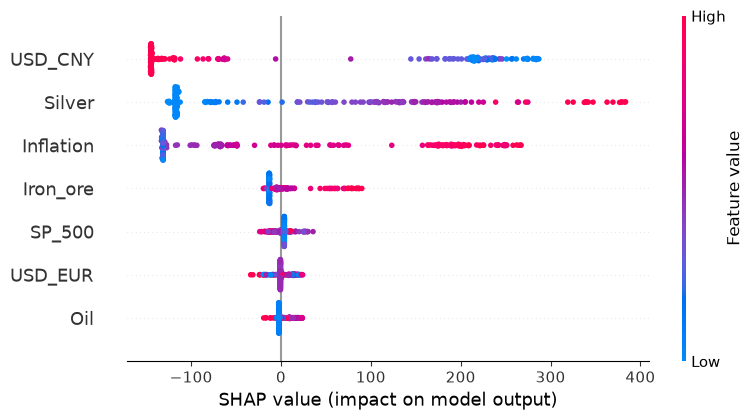

,Feature,Mean |SHAP|
0,USD_CNY,167.283630
1,Silver,131.690414
2,Inflation,131.303268
3,Iron_ore,16.959496
4,SP_500,6.596103
5,USD_EUR,5.917903
6,Oil,5.835524


In [11]:
xgb_model = trained_models["XGBoost"]
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_train)

shap.summary_plot(shap_values, X_train, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

shap.summary_plot(shap_values, X_train, show=False)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

mean_abs_shap = (pd.DataFrame({"Feature": X_train.columns,
                               "Mean |SHAP|": np.abs(shap_values).mean(axis=0)})
                 .sort_values("Mean |SHAP|", ascending=False)
                 .reset_index(drop=True))
mean_abs_shap.to_csv(f"{RESULTS_DIR}/shap_feature_importance.csv", index=False)
mean_abs_shap

### SHAP dependence plots (top 5 features)

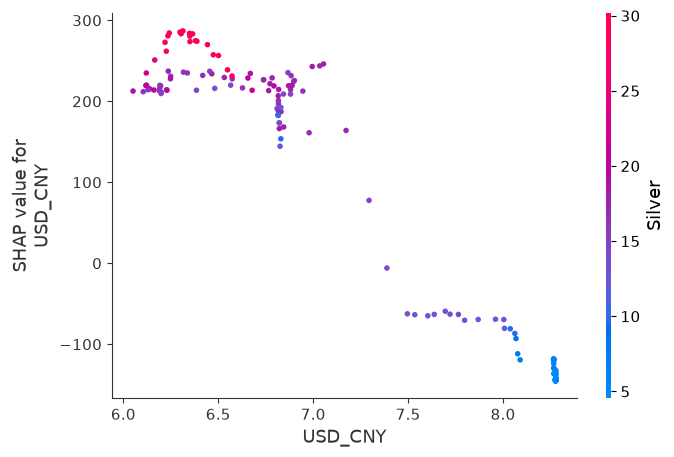

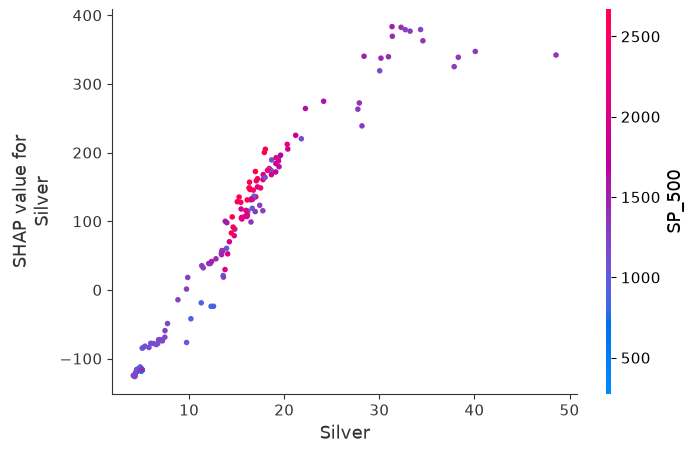

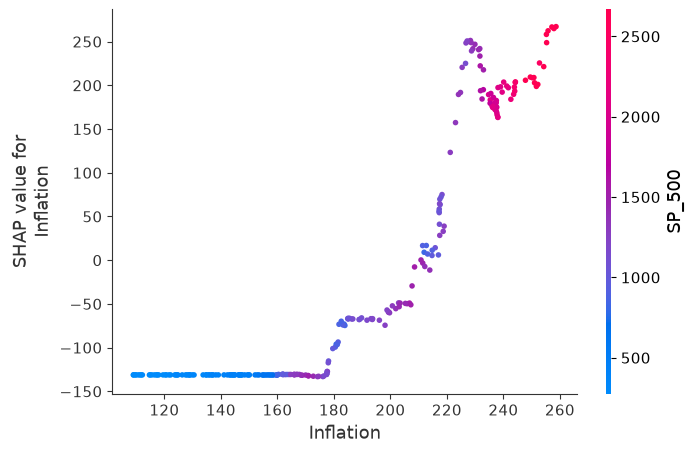

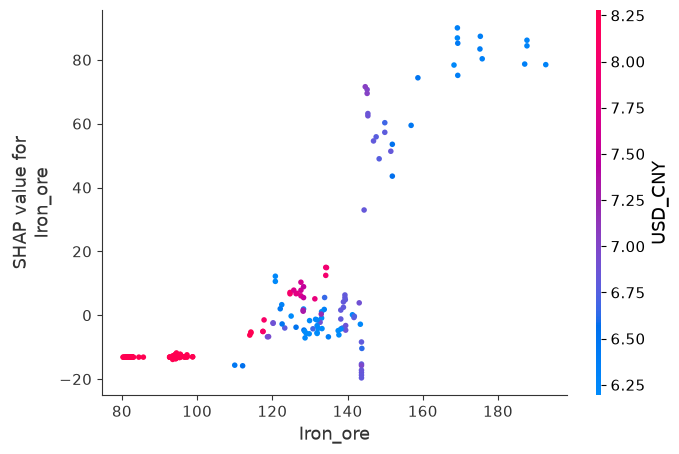

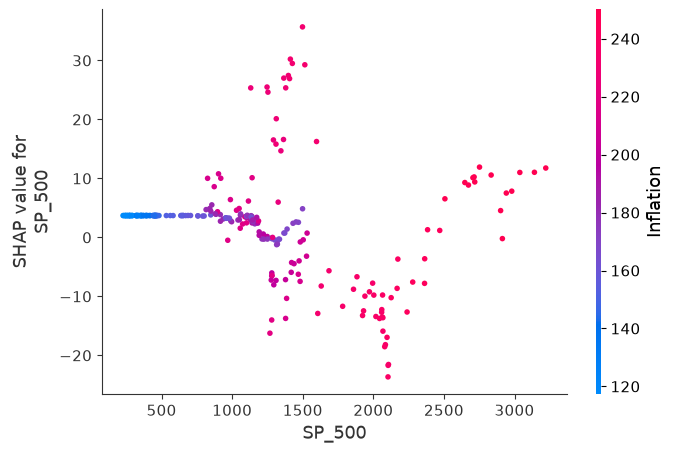

In [12]:
for feat in mean_abs_shap["Feature"].head(5):
    shap.dependence_plot(feat, shap_values, X_train, show=True)

## 11. SHAP waterfall for one test month

Background dataset has 244 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=244 when initializing the masker.


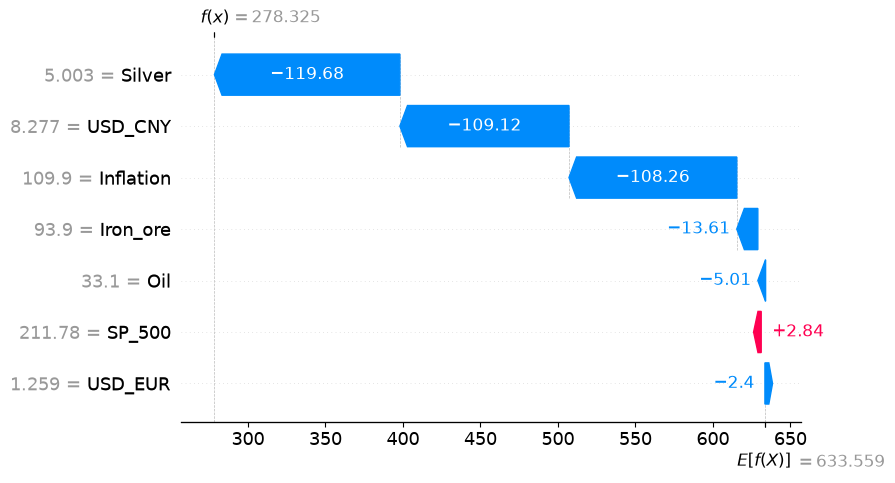

Explained month: 1986-01-01


In [13]:
explainer_test = shap.Explainer(xgb_model, X_train)
shap_values_test = explainer_test(X_test)

shap.plots.waterfall(shap_values_test[0], max_display=10, show=False)
plt.savefig(f"{RESULTS_DIR}/shap_waterfall_sample.png", dpi=150, bbox_inches="tight")
plt.show()
print("Explained month:", X_test.index[0].date())